# Full-throttle speed loss in 2026 F1 qualifying: Japanese GP

Validates FastF1 telemetry for 2026 Japanese GP qualifying (lap distance, frozen car data, usable laps), then measures full-throttle speed loss on three straights and PKE per sector, with teammate and same-PU comparisons and an external check at 130R.

**Sources.** FastF1 3.8.3: *How to perform calculations accurately* guide (HAC), Telemetry API reference (TEL), `fastf1/core.py`. Bopaiah & Samuel (2021), SAE 2021-01-0368. Segers (2014), *Analysis Techniques for Racecar Data Acquisition*, 2nd ed., SAE International.

## 0. Setup

In [1]:
import json
import warnings
import urllib.request
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fetch import load_quali

fastf1.set_log_level("WARNING")
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")  # raised inside pandas/FastF1 timedelta ops
pd.set_option("display.width", 250)
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "axes.spines.top": False,
                    "axes.spines.right": False, "savefig.bbox": "tight"})
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

OFFICIAL_LENGTH_M = 5807  # Suzuka circuit length, formula1.com
SENTINEL = 104            # Throttle value for "error or unavailable data" (core.py, Telemetry channels)
XY_UNIT_M = 0.1           # position X/Y are in 1/10 m (TEL)
WINDOW_130R = (14, 16)    # 130R = Turn 15 (Wikipedia, Suzuka Circuit; F1DA sector breakdown); window T14-T16
OPENF1_SESSION = 11249    # OpenF1 session_key for 2026 Japan qualifying
FULL_THROTTLE = 98        # Throttle >= 98 % with Brake off (planned metric)
MIN_SEGMENT_M = 500       # minimum full-throttle segment length (planned metric)
PU = {  # The Race, "What engine every F1 team is using for 2026 rules"
    "Mercedes": "Mercedes", "McLaren": "Mercedes", "Williams": "Mercedes", "Alpine": "Mercedes",
    "Ferrari": "Ferrari", "Haas F1 Team": "Ferrari", "Cadillac": "Ferrari",
    "Aston Martin": "Honda", "Red Bull Racing": "Red Bull Ford", "Racing Bulls": "Red Bull Ford", "Audi": "Audi",
}
PU_COLORS = {"Mercedes": "#0072B2", "Ferrari": "#D55E00", "Red Bull Ford": "#E69F00", "Honda": "#CC79A7",
             "Audi": "#009E73"}  # Okabe-Ito, colour-blind safe; one fixed colour per PU in every figure
STRAIGHT_COLORS = {"T13": "#4477AA", "T16": "#EE6677", "T1": "#228833"}  # Tol bright; T1 = main straight

## 1. Data

2026 Japanese GP qualifying. Corner positions come from `get_circuit_info()`; only their X/Y is used, because its `Distance` column is computed from `laps.pick_fastest()`, which here is a lap with frozen telemetry (Section 3).

In [2]:
s = load_quali(2026, "Japan")
fastest = {d: s.laps.pick_drivers(d).pick_fastest() for d in s.results["Abbreviation"]}
corners = s.get_circuit_info().corners.set_index("Number")
print(f"{s.event['EventName']} {s.name}: {len(fastest)} drivers, {s.laps['LapTime'].notna().sum()} timed laps")

Japanese Grand Prix Qualifying: 22 drivers, 227 timed laps


## 2. Validation 1: lap distance vs official length

Each fastest lap's distance from integrated car-data speed (`add_distance`) and from X/Y path length is compared with the official 5.807 km. Benchmark: < 0.6 % mean and < 1.8 % max error (Bopaiah & Samuel, 2021). X/Y distance meets it; car-data distance does not, because of frozen telemetry (Section 3).

In [3]:
def lap_pos(lap):
    """Position data padded, then sliced to the lap with interpolated edges (HAC)."""
    return lap.get_pos_data(pad=1, pad_side="both").slice_by_lap(lap, interpolate_edges=True)


def xy_cumdist(pos):
    """Cumulative X/Y path length (m) along position samples."""
    return np.r_[0, np.cumsum(np.hypot(np.diff(pos["X"]), np.diff(pos["Y"])))] * XY_UNIT_M


def lap_distance_check(laps, official_m):
    """Validation 1: distance of each lap from car data and from X/Y, with % error vs the official length."""
    v = pd.DataFrame([dict(Driver=d, PU=PU[lap["Team"]],
                           CarData_m=lap.get_car_data().add_distance()["Distance"].iloc[-1],
                           XY_m=xy_cumdist(lap_pos(lap))[-1])
                      for d, lap in laps.items()]).set_index("Driver")
    for c in ["CarData", "XY"]:
        v[f"{c}_err%"] = 100 * (v[f"{c}_m"] / official_m - 1)
    return v


v1 = lap_distance_check(fastest, OFFICIAL_LENGTH_M)
print(v1.round(2).to_string())
print("\n|error| %\n" + v1.filter(like="err%").abs().agg(["mean", "max"]).round(2).to_string())

                   PU  CarData_m     XY_m  CarData_err%  XY_err%
Driver                                                          
ANT          Mercedes    5379.28  5768.67         -7.37    -0.66
RUS          Mercedes    5772.92  5772.07         -0.59    -0.60
PIA          Mercedes    5775.35  5781.66         -0.54    -0.44
LEC           Ferrari    5774.40  5770.77         -0.56    -0.62
NOR          Mercedes    5759.21  5758.98         -0.82    -0.83
HAM           Ferrari    5755.50  5775.74         -0.89    -0.54
GAS          Mercedes    5757.97  5773.84         -0.84    -0.57
HAD     Red Bull Ford    5736.71  5760.63         -1.21    -0.80
BOR              Audi    5839.98  5774.92          0.57    -0.55
LIN     Red Bull Ford    5681.76  5774.37         -2.16    -0.56
VER     Red Bull Ford    5770.65  5769.56         -0.63    -0.64
OCO           Ferrari    5977.41  5780.00          2.93    -0.46
HUL              Audi    5791.59  5779.48         -0.27    -0.47
LAW     Red Bull Ford    

*Table 1. X/Y distance is short by 0.4–0.8 % on every lap (max 0.83 %); car-data distance errs by up to 7.37 % (ANT).*

## 3. Telemetry freezes

Car-data channels sometimes stop updating while the car is running: Speed, RPM and gear hold their last value and Throttle reads 104. FastF1 documents 104 as an error value that usually occurs only when the car is stationary; 104 during running is our observation. **Definition:** seed on `Throttle == 104`, extend to the surrounding run of unchanged Speed + RPM + nGear, and add a 1-sample buffer on each side. Brake is unreliable inside a freeze (104 is cast to `True`).

In [4]:
def freeze_mask(car):
    """Frozen samples. Returns (flagged incl. 1-sample buffer, core run without buffer, run id)."""
    k = ["Speed", "RPM", "nGear"]
    run_id = car[k].ne(car[k].shift()).any(axis=1).cumsum()
    core = run_id.isin(run_id[car["Throttle"] == SENTINEL])
    return core | core.shift(1, fill_value=False) | core.shift(-1, fill_value=False), core, run_id


def blocks(car, mask, end):
    """Contiguous True blocks of `mask` as (i0, i1, t0, t1), times in session seconds.
    A block lasts until the next sample, or until `end` for the last one."""
    t = np.append(car["SessionTime"].dt.total_seconds().to_numpy(), end.total_seconds())
    e = np.diff(np.r_[0, mask.to_numpy().astype(int), 0])
    i0, i1 = np.flatnonzero(e == 1), np.flatnonzero(e == -1)
    return list(zip(i0, i1, t[i0], t[i1]))


def frozen_between(lap, car, ta, tb):
    """True if a flagged freeze overlaps session time (ta, tb) in seconds."""
    return any(a < tb and b > ta for _, _, a, b in blocks(car, freeze_mask(car)[0], lap["Time"]))


def xy_path(pos, t0, t1):
    """X/Y path length (m) and elapsed time (s) between the position samples nearest t0 and t1 (no interpolation)."""
    pt = pos["SessionTime"].dt.total_seconds().to_numpy()
    a, b = np.abs(pt - t0).argmin(), np.abs(pt - t1).argmin()
    return xy_cumdist(pos.iloc[a:b + 1])[-1], pt[b] - pt[a]

### 3.1 Example

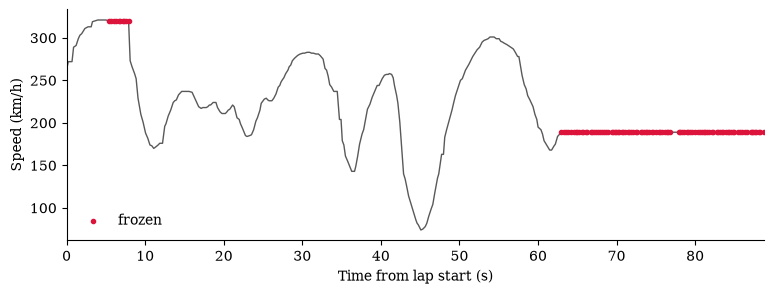

In [5]:
lap = fastest["ANT"]
car = lap.get_car_data()
_, core, _ = freeze_mask(car)
t = (car["SessionTime"] - lap["LapStartTime"]).dt.total_seconds()

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t, car["Speed"], color="0.35", lw=1)
ax.scatter(t[core], car["Speed"][core], s=9, color="crimson", zorder=3, label="frozen")
ax.set(xlabel="Time from lap start (s)", ylabel="Speed (km/h)", xlim=(0, lap["LapTime"].total_seconds()))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.show()

*Figure 1. ANT's pole lap: car data freezes at 189 km/h for the final 25.8 s, and briefly at 320 km/h on the start straight.*

### 3.2 Definition check and X/Y confirmation

On the 22 fastest laps: do 104 samples sit inside unchanged runs, and does the frozen Speed disagree with the mean speed implied by X/Y path length over the same window? This follows the approach of comparing an in-car measurement with an independently obtained expected value (Segers, 2014, sec. 3.6 by G. Callea, p. 72). Speed is not reconstructed from X/Y, so agreement cannot rule a freeze out. The same freeze appears in OpenF1 (Appendix A), so it originates upstream of FastF1.

In [6]:
runs, seeds, frozen_pct = [], [], {}
for d, lap in fastest.items():
    car = lap.get_car_data()
    pos = lap.get_pos_data(pad=1, pad_side="both")
    flag, core, run_id = freeze_mask(car)
    frozen_pct[d] = 100 * flag.mean()
    seeds.append(run_id.map(run_id.value_counts())[car["Throttle"] == SENTINEL])
    for i0, i1, t0, t1 in blocks(car, core, lap["Time"]):
        m, dt = xy_path(pos, t0, t1)
        runs.append(dict(Driver=d, Samples=i1 - i0, Duration_s=t1 - t0,
                         FrozenSpeed=car["Speed"].iloc[i0], XYSpeed=3.6 * m / dt if dt > 0 else np.nan))
seeds = pd.concat(seeds)
print(f"Throttle == 104 samples: {len(seeds)}; inside an unchanged run: {(seeds > 1).sum()}; isolated: {(seeds == 1).sum()}\n")

runs = pd.DataFrame(runs).assign(AbsDiff_kmh=lambda x: (x.FrozenSpeed - x.XYSpeed).abs())
runs["Duration"] = pd.cut(runs.Duration_s, [0, 1, 3, np.inf], right=False, labels=["< 1 s", "1-3 s", ">= 3 s"])
print(runs.groupby("Duration", observed=True)["AbsDiff_kmh"].agg(["size", "mean", "max"]).round(1).to_string())

Throttle == 104 samples: 745; inside an unchanged run: 730; isolated: 15

          size  mean    max
Duration                   
< 1 s        2  28.8   51.0
1-3 s       30  21.5   69.7
>= 3 s      29  35.4  139.1


*Table 2. |Frozen Speed − X/Y mean speed| by freeze duration: 730 of 745 sentinel samples sit inside unchanged runs; long freezes are off by 35 km/h on average (max 139 km/h).*

### 3.3 Prevalence on fastest laps

In [7]:
fl = pd.DataFrame({"PU": {d: PU[lap["Team"]] for d, lap in fastest.items()}, "FrozenPct": frozen_pct})
print(fl.groupby("PU")["FrozenPct"].agg(Drivers="size", MeanFrozenPct="mean", MinPct="min", MaxPct="max")
      .round(1).sort_values("MeanFrozenPct", ascending=False).to_string())

               Drivers  MeanFrozenPct  MinPct  MaxPct
PU                                                   
Audi                 2           33.1    30.7    35.5
Mercedes             8           17.5     0.0    40.2
Red Bull Ford        4           10.6     2.9    24.4
Ferrari              6            9.5     0.0    37.6
Honda                2            8.1     4.2    12.1


*Table 3. Share of each fastest lap flagged as frozen, by PU: from 0 % to 40 % per lap; both Audi laps exceed 30 %.*

### 3.4 Simultaneity across cars

Do freezes hit many cars at once (a feed-wide outage) or one car at a time? For every freeze overlapping a driver's laps (whole-session car data), count other cars frozen at its midpoint, against a baseline of random on-track moments (random lap, uniform time within it; seed 0).

In [8]:
fr = []
for d in s.results["Abbreviation"]:
    dl = s.laps.pick_drivers(d)
    car = s.car_data[dl["DriverNumber"].iloc[0]]
    on = list(zip(dl["LapStartTime"].dt.total_seconds(), dl["Time"].dt.total_seconds()))
    fr += [dict(Driver=d, t0=t0, t1=t1) for _, _, t0, t1 in blocks(car, freeze_mask(car)[1], car["SessionTime"].iloc[-1])
           if any(a < t1 and b > t0 for a, b in on)]
fr = pd.DataFrame(fr).assign(Duration_s=lambda x: x.t1 - x.t0)


def others_frozen_at(t, driver):
    return fr[(fr.Driver != driver) & (fr.t0 <= t) & (fr.t1 > t)].Driver.nunique()


fr["OthersAtMid"] = [others_frozen_at((a + b) / 2, d) for d, a, b in zip(fr.Driver, fr.t0, fr.t1)]
rng = np.random.default_rng(0)
lw = s.laps.dropna(subset=["LapStartTime", "Time"])
smp = lw.iloc[rng.integers(0, len(lw), 2000)]
t_rand = smp["LapStartTime"].dt.total_seconds() + rng.random(len(smp)) * (smp["Time"] - smp["LapStartTime"]).dt.total_seconds()
base = pd.Series([others_frozen_at(t, d) for t, d in zip(t_rand, smp["Driver"])])

groups = {"freeze midpoints": fr.OthersAtMid, "freeze midpoints (>= 3 s)": fr.OthersAtMid[fr.Duration_s >= 3],
          "random on-track moments": base}
print(pd.DataFrame({k: {"n": len(v), "mean other cars frozen": v.mean(), ">= 5 other cars": (v >= 5).mean()}
                    for k, v in groups.items()}).T.round(2).to_string())

                                n  mean other cars frozen  >= 5 other cars
freeze midpoints            937.0                    4.33             0.41
freeze midpoints (>= 3 s)   492.0                    4.42             0.44
random on-track moments    2000.0                    3.65             0.31


*Table 4. Other cars frozen at the same instant: 4.3 at freeze midpoints vs 3.7 at random moments, so freezes are frequent (937 in the session) but only weakly synchronised.*

## 4. Push-lap selection and coverage

Using only fastest laps leaves 8 of 22 drivers with clean data through 130R. Freezes vary from lap to lap, so each driver's best clean push lap is used instead. **Push lap:** timed, `pick_wo_box()` (no in/out laps), `pick_quicklaps()` (≤ 107 % of session best; removes cool-down and aborted laps), `pick_not_deleted()`. **Clean through a window:** no flagged freeze overlaps the time between passing the two corners (position sample nearest each corner's X/Y). **Selection, per driver per window:** latest quali part with a clean lap, then fastest lap within it; `QualiPart` is kept with every selection.

In [9]:
def push_laps(session):
    """Push laps with QualiPart, and a log of excluded timed laps with reasons."""
    timed = session.laps[session.laps["LapTime"].notna()]
    part = pd.concat([l["LapNumber"].to_frame().assign(QualiPart=f"Q{i}")
                      for i, l in enumerate(session.laps.split_qualifying_sessions(), 1) if l is not None])["QualiPart"]
    reason = pd.Series("", index=timed.index)
    reason[~timed.index.isin(timed.pick_wo_box().index)] = "in/out lap"
    reason[(reason == "") & ~timed.index.isin(timed.pick_quicklaps().index)] = "slower than 107 % (cool-down/aborted)"
    reason[(reason == "") & timed["Deleted"]] = "deleted: " + timed["DeletedReason"].str.strip()
    timed = timed.assign(QualiPart=part)
    log = timed.loc[reason != "", ["Driver", "LapNumber", "QualiPart"]].assign(Reason=reason)
    return timed.loc[reason == ""], log


def corner_times(lap, numbers, corners):
    """Session time (s) of the position sample nearest each corner's X/Y."""
    pos = lap.get_pos_data(pad=1, pad_side="both")
    pt = pos["SessionTime"].dt.total_seconds().to_numpy()
    return [pt[np.hypot(pos.X - corners.loc[n, "X"], pos.Y - corners.loc[n, "Y"]).argmin()] for n in numbers]


def clean_through(lap, corners, window=WINDOW_130R):
    """True if no flagged freeze overlaps the time between the two corners of `window`."""
    ta, tb = sorted(corner_times(lap, window, corners))
    return not frozen_between(lap, lap.get_car_data(), ta, tb)


def best_clean_lap(clean_rows, by="Driver"):
    """One row per group of already-clean rows: latest quali part first, then fastest lap within it."""
    return clean_rows.sort_values(["QualiPart", "LapTime"], ascending=[False, True]).groupby(by).head(1)


push, lap_log = push_laps(s)
timed = s.laps[s.laps["LapTime"].notna()]
qc = pd.DataFrame([dict(Driver=lap["Driver"], LapNumber=int(lap["LapNumber"]), Push=i in push.index,
                        FrozenPct=100 * freeze_mask(lap.get_car_data())[0].mean(), Clean130R=clean_through(lap, corners))
                   for i, lap in timed.iterlaps()], index=timed.index)
clean130 = qc.loc[push.index, "Clean130R"]
sel130 = best_clean_lap(push[clean130])

pq = qc[qc.Push].groupby("Driver")["FrozenPct"]
print(f"Push laps: {len(push)} of {len(timed)} timed; drivers with both a freeze-free and a frozen push lap: "
      f"{((pq.min() == 0) & (pq.max() > 0)).sum()} / {pq.ngroups}\n")
cov = pd.DataFrame({"Drivers": pd.Series({d: PU[l["Team"]] for d, l in fastest.items()}).value_counts(),
                    "Clean fastest lap": pd.Series({d: PU[l["Team"]] for d, l in fastest.items() if qc.loc[l.name, "Clean130R"]}).value_counts(),
                    "Clean push lap selected": sel130["Team"].map(PU).value_counts()}).fillna(0).astype(int)
cov.loc["Total"] = cov.sum()
print(cov.to_string())

Push laps: 108 of 227 timed; drivers with both a freeze-free and a frozen push lap: 16 / 22

               Drivers  Clean fastest lap  Clean push lap selected
Audi                 2                  0                        2
Ferrari              6                  2                        5
Honda                2                  1                        2
Mercedes             8                  3                        8
Red Bull Ford        4                  2                        4
Total               22                  8                       21


*Table 5. Drivers with clean data through 130R (T14–T16), by PU: 8 of 22 using fastest laps, 21 of 22 using the best clean push lap; only OCO has none.*

In [10]:
order = [d for d in s.results["Abbreviation"] if d in set(sel130["Driver"])]
print(sel130.assign(PU=sel130["Team"].map(PU), LapTime_s=sel130["LapTime"].dt.total_seconds())
      .set_index("Driver").loc[order, ["PU", "QualiPart", "LapNumber", "LapTime_s"]].to_string())

                   PU QualiPart  LapNumber  LapTime_s
Driver                                               
ANT          Mercedes        Q3       14.0     88.839
RUS          Mercedes        Q3       17.0     89.076
PIA          Mercedes        Q3       16.0     89.132
LEC           Ferrari        Q3       17.0     89.405
NOR          Mercedes        Q3       16.0     89.409
HAM           Ferrari        Q3       16.0     89.567
GAS          Mercedes        Q1        2.0     90.765
HAD     Red Bull Ford        Q3       14.0     89.978
BOR              Audi        Q3       16.0     90.648
LIN     Red Bull Ford        Q2       11.0     90.694
VER     Red Bull Ford        Q2       11.0     90.262
HUL              Audi        Q1        4.0     90.542
LAW     Red Bull Ford        Q1        8.0     90.657
COL          Mercedes        Q1        2.0     91.458
SAI          Mercedes        Q1        5.0     91.676
ALB          Mercedes        Q1        5.0     91.510
BEA           Ferrari       

*Table 6. Lap selected per driver for 130R: 8 from Q3, 2 from Q2, 11 from Q1, so `QualiPart` must travel with every measurement.*

## 5. Exclusion log

Every timed lap not used for 130R, with the reason. Deleted laps are excluded: Japan's one deleted lap (track limits at T13, Spoon) affects exit speed onto the back straight, which feeds the measured straight to 130R.

In [11]:
excl = pd.concat([
    lap_log.assign(Scope="lap"),
    push.loc[~clean130, ["Driver", "LapNumber", "QualiPart"]].assign(Scope="130R", Reason="freeze overlaps T14-T16"),
    push.loc[clean130 & ~push.index.isin(sel130.index), ["Driver", "LapNumber", "QualiPart"]]
        .assign(Scope="130R", Reason="clean, not selected (earlier part or slower)"),
])
print(excl.groupby(["Scope", "Reason"]).size().rename("laps").to_string())
print("\nNo clean lap through 130R:", sorted(set(fastest) - set(sel130["Driver"])))

Scope  Reason                                      
130R   clean, not selected (earlier part or slower)    36
       freeze overlaps T14-T16                         51
lap    deleted: TRACK LIMITS AT TURN 13 LAP 18          1
       in/out lap                                      99
       slower than 107 % (cool-down/aborted)           19

No clean lap through 130R: ['OCO']


*Table 7. Of 227 timed laps, 119 fail the push-lap filter; of the 108 push laps, 51 have a freeze in T14–T16, 36 are clean but not selected, and 21 are used.*

## 6. Sector PKE and full-throttle segments

**A. Sectors** (partial replication of Bopaiah & Samuel, 2021, pp. 4-5; coverage is limited by freezes): each push lap is split into the three FIA sectors with FastF1 sector timestamps (`LapStartTime`, `Sector1SessionTime`, `Sector2SessionTime`, `Sector3SessionTime`), and PKE is computed per sector and for the full lap with their eq. 4. **B. Straights** (our refinement): full-throttle segments (Throttle >= 98, Brake off, single-sample dips merged, >= 500 m), labelled by the corner they end at (X/Y), with clipping metrics and the C5.2.8 taper power at peak speed. Sectors and segments that overlap a freeze are dropped and logged; each driver's best clean lap is then used per sector or straight (latest quali part first, then fastest). Distances are car-data distances within the interval.

In [12]:
def pke(car):
    """Positive kinetic energy, eq. 4 of Bopaiah & Samuel (2021): sum(Vf^2 - Vi^2) over steps with Vf > Vi,
    divided by the interval distance x. V in m/s, x in m; result in m/s^2."""
    v = car["Speed"].to_numpy() / 3.6
    dv2 = np.diff(v ** 2)
    x = car["Distance"].iloc[-1] - car["Distance"].iloc[0]
    return dv2[dv2 > 0].sum() / x if x > 0 else np.nan


def taper_kw(v):
    """Max ERS-K power used to propel the car (kW) at speed v (km/h), outside Override Mode."""
    v = np.asarray(v, dtype=float)
    p = np.where(v < 340, 1800 - 5 * v, 6900 - 20 * v)  # FIA 2026 Tech Regs C5.2.8 i
    p = np.where(v >= 345, 0, p)                         # FIA 2026 Tech Regs C5.2.8 i
    return np.minimum(p, 350)                            # FIA 2026 Tech Regs C5.2.7 (350 kW cap)


def lap_geometry(lap, corners):
    """X/Y lap position (m) of each position sample, their session times (s), and each corner's lap position."""
    pos = lap_pos(lap)
    xyd, pt = xy_cumdist(pos), pos["SessionTime"].dt.total_seconds().to_numpy()
    return xyd, pt, {n: xyd[np.hypot(pos.X - c.X, pos.Y - c.Y).argmin()] for n, c in corners.iterrows()}


def position_at(xyd, pt, times):
    """Lap position (X/Y m) at each session time in `times`, via the nearest position sample (no interpolation)."""
    t = times.dt.total_seconds().to_numpy()
    return xyd[np.abs(pt[:, None] - t[None, :]).argmin(axis=0)]


def meta(lap):
    return dict(Driver=lap["Driver"], Team=lap["Team"], PU=PU[lap["Team"]], LapNumber=int(lap["LapNumber"]),
                QualiPart=lap["QualiPart"], LapTime=lap["LapTime"])


def full_throttle_segments(car, end):
    """(i0, i1) sample ranges of full-throttle segments >= MIN_SEGMENT_M; single-sample dips are merged."""
    ft = (car["Throttle"] >= FULL_THROTTLE) & ~car["Brake"]
    ft = ft | (ft.shift(1, fill_value=False) & ft.shift(-1, fill_value=False))
    d = car["Distance"].to_numpy()
    return [(a, b) for a, b, _, _ in blocks(car, ft, end) if d[b - 1] - d[a] >= MIN_SEGMENT_M]


SECTORS = {"S1": ("LapStartTime", "Sector1SessionTime"), "S2": ("Sector1SessionTime", "Sector2SessionTime"),
           "S3": ("Sector2SessionTime", "Sector3SessionTime"), "Full": ("LapStartTime", "Time")}


def segment_metrics(seg):
    """Clipping metrics for one segment. The peak is the last sample at maximum speed."""
    sp, d = seg["Speed"].to_numpy(), seg["Distance"].to_numpy()
    k = len(sp) - 1 - np.argmax(sp[::-1])
    length, after = d[-1] - d[0], d[-1] - d[k]
    return dict(start_m=d[0], end_m=d[-1], peak_m=d[k], length_m=length,
                peak_speed=sp[k], end_speed=sp[-1], clip_delta=sp[k] - sp[-1], clip_distance=after,
                decel_rate=100 * (sp[k] - sp[-1]) / after if after > 0 else np.nan,
                vmax_position=(d[k] - d[0]) / length, taper_kw_at_peak=float(taper_kw(sp[k])), pke=pke(seg))


def sector_segment_rows(push, corners):
    """One row per push lap and sector (PKE, Frozen) and per full-throttle segment (label, metrics, Frozen, Truncated)."""
    sec_rows, seg_rows = [], []
    for _, lap in push.iterlaps():
        car = lap.get_car_data().add_distance()
        flag = freeze_mask(car)[0]
        st = car["SessionTime"]
        for name, (a, b) in SECTORS.items():
            ta, tb = lap[a], lap[b]
            frozen = pd.isna(ta) or pd.isna(tb) or frozen_between(lap, car, ta.total_seconds(), tb.total_seconds())
            sec_rows.append(dict(meta(lap), Sector=name, Frozen=frozen,
                                 PKE=np.nan if frozen else pke(car[(st >= ta) & (st <= tb)])))

        xyd, pt, cpos = lap_geometry(lap, corners)
        for i0, i1 in full_throttle_segments(car, lap["Time"]):
            p0, p1 = position_at(xyd, pt, st.iloc[[i0, i1 - 1]])
            ahead = [n for n, x in cpos.items() if x > p1]
            seg_rows.append(dict(meta(lap), Label=f"T{min(ahead, key=cpos.get)}" if ahead else "lap end",
                                 Via=",".join(f"T{n}" for n, x in cpos.items() if p0 < x < p1),
                                 StartPos_m=p0, EndPos_m=p1, Truncated=i0 == 0 or i1 == len(car),
                                 Frozen=bool(flag.iloc[i0:i1].any()), **segment_metrics(car.iloc[i0:i1])))
    return pd.DataFrame(sec_rows), pd.DataFrame(seg_rows)


def line_window(session, lap, window_s=30):
    """Whole-session car data within ±window_s of the lap start, Distance = 0 at the timing line,
    and the index of the first sample after the line."""
    t_line = lap["LapStartTime"]
    car = (session.car_data[lap["DriverNumber"]]
           .slice_by_time(t_line - pd.Timedelta(seconds=window_s), t_line + pd.Timedelta(seconds=window_s)).add_distance())
    st = car["SessionTime"].dt.total_seconds()
    car["Distance"] -= np.interp(t_line.total_seconds(), st, car["Distance"])
    return car, int(np.searchsorted(st.to_numpy(), t_line.total_seconds()))


def main_straight_rows(session, push, window_s=30):
    """Full-throttle segment containing the timing line, from whole-session car data within ±window_s of each push
    lap's start. Distances are relative to the line; Status says whether the segment is usable."""
    rows = []
    for _, lap in push.iterlaps():
        car, k = line_window(session, lap, window_s)
        hit = [(a, b) for a, b in full_throttle_segments(car, car["SessionTime"].iloc[-1]) if a < k < b]
        if not hit:
            rows.append(dict(meta(lap), Status="no full-throttle segment across the line"))
            continue
        a, b = hit[0]
        status = ("cut by ±30 s window" if a == 0 or b == len(car)
                  else "overlaps freeze" if freeze_mask(car)[0].iloc[a:b].any() else "ok")
        rows.append(dict(meta(lap), Status=status, **segment_metrics(car.iloc[a:b])))
    return pd.DataFrame(rows)


def select_clean(sec_all, seg_all, ms_all):
    """Best clean lap per driver for each sector, straight and the main straight (latest quali part, then fastest).
    Returns sectors, straights, main straight, and straights + main straight combined."""
    sectors = best_clean_lap(sec_all[~sec_all.Frozen], by=["Driver", "Sector"])
    straights = best_clean_lap(seg_all[~seg_all.Frozen & ~seg_all.Truncated], by=["Driver", "Label"])
    main = best_clean_lap(ms_all[ms_all.Status == "ok"]).assign(Label="T1", Via="timing line", CrossesTimingLine=True)
    return sectors, straights, main, pd.concat([straights.assign(CrossesTimingLine=False), main], ignore_index=True)

### 6.1 Computation

In [13]:
sec_all, seg_all = sector_segment_rows(push, corners)
ms_all = main_straight_rows(s, push)
sectors, straights, main_straight, segments = select_clean(sec_all, seg_all, ms_all)

seg_log = seg_all[seg_all.Frozen | seg_all.Truncated].assign(
    Reason=lambda x: np.where(x.Frozen, "overlaps freeze", "truncated by lap boundary"))
print(f"Sectors: {len(sec_all)} computed, {sec_all.Frozen.sum()} dropped (freeze), {len(sectors)} selected")
print(f"Segments: {len(seg_all)} detected, {len(seg_log)} dropped, {len(straights)} selected")
print("\nDropped segments by label:\n" + seg_log.groupby(["Label", "Reason"]).size().rename("n").to_string())
missing = {k: sorted(set(fastest) - set(sectors.loc[sectors.Sector == k, "Driver"])) for k in SECTORS}
print("\nDrivers with no clean sector:", {k: v for k, v in missing.items() if v})

Sectors: 432 computed, 241 dropped (freeze), 75 selected
Segments: 271 detected, 123 dropped, 43 selected

Dropped segments by label:
Label  Reason                   
T1     overlaps freeze               6
       truncated by lap boundary    73
T13    overlaps freeze              12
T15    overlaps freeze              15
T16    overlaps freeze               6
T2     truncated by lap boundary    11

Drivers with no clean sector: {'S2': ['BOT', 'OCO'], 'S3': ['ALO', 'BEA', 'BOT', 'OCO', 'STR'], 'Full': ['ALO', 'BEA', 'BOT', 'GAS', 'OCO', 'STR']}


### 6.2 Team-to-PU mapping

In [14]:
print(s.results[["TeamName"]].drop_duplicates().assign(PU=lambda x: x.TeamName.map(PU)).to_string(index=False))

       TeamName            PU
       Mercedes      Mercedes
        McLaren      Mercedes
        Ferrari       Ferrari
         Alpine      Mercedes
Red Bull Racing Red Bull Ford
           Audi          Audi
   Racing Bulls Red Bull Ford
   Haas F1 Team       Ferrari
       Williams      Mercedes
       Cadillac       Ferrari
   Aston Martin         Honda


*Table 8. Team-to-PU mapping applied to every row, verified against The Race, "What engine every F1 team is using for 2026 rules".*

### 6.3 Sanity checks

In [15]:
print("Full-throttle segments per push lap:", seg_all.groupby(["Driver", "LapNumber"]).size().value_counts().sort_index().to_dict(), "\n")
print(straights.groupby("Label").agg(Drivers=("Driver", "size"), Via=("Via", lambda x: x.mode().iat[0]),
                                    StartPos_m=("StartPos_m", "median"), EndPos_m=("EndPos_m", "median"),
                                    EndPos_IQR_m=("EndPos_m", lambda x: x.quantile(.75) - x.quantile(.25)),
                                    Length_m=("length_m", "median"))
      .sort_values("EndPos_m").round(0).to_string())

Full-throttle segments per push lap: {1: 8, 2: 31, 3: 67} 

       Drivers  Via  StartPos_m  EndPos_m  EndPos_IQR_m  Length_m
Label                                                            
T13         22  T12      2966.0    3685.0          44.0     719.0
T16         21  T15      4029.0    5232.0          12.0    1208.0


*Table 9. Only two straights yield clean, untruncated segments: T12 to T13 (22 drivers) and T14 to T16 through 130R (21 drivers); segment end positions agree across drivers within 44 m (IQR).*

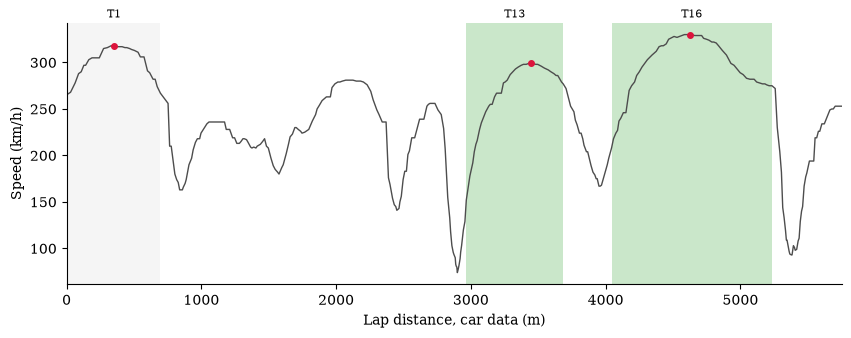

RUS lap 14 (Q2)


In [16]:
drv = "RUS" if ((sectors.Driver == "RUS") & (sectors.Sector == "Full")).any() else sectors.loc[sectors.Sector == "Full", "Driver"].iat[0]
lapno = sectors.loc[(sectors.Driver == drv) & (sectors.Sector == "Full"), "LapNumber"].iat[0]
lap = push[(push.Driver == drv) & (push.LapNumber == lapno)].iloc[0]
car = lap.get_car_data().add_distance()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(car["Distance"], car["Speed"], color="0.3", lw=1)
for _, g in seg_all[(seg_all.Driver == drv) & (seg_all.LapNumber == lapno)].iterrows():
    ax.axvspan(g.start_m, g.end_m, color="0.85" if g.Truncated else "tab:green", alpha=0.25, lw=0)
    ax.plot(g.peak_m, g.peak_speed, "o", color="crimson", ms=4)
    ax.text((g.start_m + g.end_m) / 2, 1.02, g.Label, transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
ax.set(xlabel="Lap distance, car data (m)", ylabel="Speed (km/h)", xlim=(0, car["Distance"].iloc[-1]))
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"{drv} lap {lapno} ({lap['QualiPart']})")

*Figure 2. RUS lap 14 (Q2, freeze-free): green = selected full-throttle segments with peak speed (red); grey = main-straight segment cut by the start/finish line.*

In [17]:
print(straights.groupby("Label")[["peak_speed", "end_speed", "clip_delta", "clip_distance", "decel_rate", "vmax_position", "taper_kw_at_peak"]]
      .mean().round(1).sort_values("clip_delta", ascending=False).to_string())

       peak_speed  end_speed  clip_delta  clip_distance  decel_rate  vmax_position  taper_kw_at_peak
Label                                                                                               
T16         328.0      272.2        55.8          607.2         9.2            0.5             159.8
T13         293.4      270.5        22.9          248.2         9.0            0.7             329.8


*Table 10. Mean clipping metrics per straight: the 130R straight (ending T16) loses 55.8 km/h after a 328 km/h peak; the straight ending T13 loses 22.9 km/h.*

### 6.4 Main straight (crosses timing line)

The start/finish line splits the main straight between two laps, so it is measured on the car data around each push lap's start (±30 s, whole-session car data): the full-throttle segment containing the line, with both sides (end of the previous lap, start of the push lap) freeze-free. These rows are flagged `CrossesTimingLine`: energy is accounted per lap at the timing line (FIA 2026 Tech Regs C5.2.2), so the segment spans two energy laps. Distances are relative to the timing line. Reported separately from the other straights.

In [18]:
print(ms_all.Status.value_counts().to_string())
print(f"\nMain straight selected for {len(main_straight)} / {len(fastest)} drivers\n")
print(main_straight[["Driver", "PU", "QualiPart", "start_m", "end_m", "peak_speed", "end_speed", "clip_delta", "clip_distance", "decel_rate"]]
      .set_index("Driver").reindex([d for d in fastest if d in set(main_straight.Driver)]).round(1).to_string())

Status
ok                                          65
overlaps freeze                             22
no full-throttle segment across the line    21

Main straight selected for 21 / 22 drivers

                   PU QualiPart  start_m  end_m  peak_speed  end_speed  clip_delta  clip_distance  decel_rate
Driver                                                                                                       
ANT          Mercedes        Q2    -79.6  713.6       313.0      260.0        53.0          376.4        14.1
RUS          Mercedes        Q3    -89.5  702.6       323.0      268.0        55.0          302.4        18.2
PIA          Mercedes        Q3   -138.6  665.2       326.0      283.0        43.0          300.1        14.3
LEC           Ferrari        Q3   -124.8  638.6       330.0      297.0        33.0          219.2        15.1
NOR          Mercedes        Q3   -109.9  674.6       321.0      271.0        50.0          333.3        15.0
HAM           Ferrari        Q3   -11

*Table 12. Main straight (crosses the timing line), 21 of 22 drivers (ALO has no freeze-free crossing): segments start 80–170 m before the line; clip_delta ranges from 10 km/h (BOR) to 59 km/h (OCO).*

In [19]:
print(sectors.pivot(index="Driver", columns="Sector", values="PKE").reindex(list(fastest))[["S1", "S2", "S3", "Full"]].round(2).to_string())

Sector    S1    S2    S3  Full
Driver                        
ANT     3.87  6.53  4.53  5.10
RUS     4.14  6.57  4.53  5.15
PIA     3.99  6.44  4.73  5.14
LEC     3.95  6.07  4.75  4.98
NOR     3.62  6.40  4.70  5.00
HAM     3.73  5.93  4.74  4.86
GAS     4.39  6.48  4.77   NaN
HAD     4.03  6.64  4.70  5.32
BOR     4.05  6.43  4.51  5.16
LIN     3.80  6.74  4.54  5.20
VER     4.08  6.55  4.72  5.19
OCO     4.09   NaN   NaN   NaN
HUL     3.93  6.54  4.94  5.37
LAW     3.79  6.90  4.71  5.26
COL     4.53  6.49  4.96  5.41
SAI     4.06  6.66  4.73  5.43
ALB     4.17  6.63  4.65  5.21
BEA     3.84  6.30   NaN   NaN
PER     4.27  6.55  4.18  5.20
BOT     4.22   NaN   NaN   NaN
ALO     5.49  6.03   NaN   NaN
STR     3.70  5.90   NaN   NaN


*Table 11. PKE per sector and full lap (m/s², best clean lap per driver and sector): S2 is highest for every driver. Coverage: S1 22, S2 20, S3 17, full lap 16 of 22 drivers.*

### 6.5 Output

In [20]:
Path("data").mkdir(exist_ok=True)
def to_seconds(df):
    return df.assign(LapTime=df["LapTime"].dt.total_seconds()).rename(columns={"LapTime": "LapTime_s"})


to_seconds(sectors).to_csv("data/japan_sectors.csv", index=False)
to_seconds(segments).to_csv("data/japan_segments.csv", index=False)
print(f"data/japan_sectors.csv: {len(sectors)} rows; data/japan_segments.csv: {len(segments)} rows")

data/japan_sectors.csv: 75 rows; data/japan_segments.csv: 64 rows


## 7. Validation 2: speed loss at 130R

130R (T15) is a flat-out corner inside the T14-T16 full-throttle segment, not the segment end. Pre-specified definition (primary), matching F1Technical's "minimum speed recorded at 130R": peak speed before T15, then minimum speed from that peak to T15 + 100 m (X/Y lap position). Sensitivity: minimum from the peak to the segment end. The segment-end window ends at the last full-throttle sample before the driver lifts or brakes for T16. Segers (2014, p. 52) describes the end of a straight as where top speed is reached just before braking; The Race ("Why key 2026 F1 rules fix will create another problem", 20 Apr 2026) reports that Vmax should peak late on a straight but with 2026 cars peaks earlier and gradually declines; on the T14-T16 segment, mean `vmax_position` is 0.48 (median 0.50, n = 21). clip_delta measures the full-throttle speed lost between the peak and that point. F1Technical's figures are closest to this window (Table 13). Both are computed on our cleaned laps (selected T16 segment) and, as a check, on each driver's raw fastest lap (`pick_fastest`, no freeze mask, no push-lap selection), averaged per team. F1Technical does not state its data source, the driver or lap per team, or the exact minimum-speed location; if it uses the same public timing feed it may contain the same freezes. It is an approximate reference, not ground truth.

In [21]:
F1T_130R = {  # F1Technical, "F1MATHS ... superclipping ... Suzuka" (f1technical.net/news/28392): (peak, minimum) km/h
    "Audi": (329, 278), "Aston Martin": (327, 267), "Red Bull Racing": (330, 274),
    "Racing Bulls": (333, 276), "Alpine": (333, 278), "Mercedes": (329, 271),  # Mercedes listed as "53 km/h" in source
}


def speed_130r(lap):
    """On the full-throttle segment containing T15: peak speed before T15, minimum from that peak to T15 + 100 m
    (primary) and to the segment end (sensitivity), and whether a freeze overlaps T14-T16. No freeze filtering."""
    car = lap.get_car_data().add_distance()
    xyd, pt, cpos = lap_geometry(lap, corners)
    frozen = frozen_between(lap, car, *sorted(corner_times(lap, (14, 16), corners)))
    for a, b in full_throttle_segments(car, lap["Time"]):
        p0, p1 = position_at(xyd, pt, car["SessionTime"].iloc[[a, b - 1]])
        if p0 < cpos[15] < p1:
            break
    else:
        return dict(Peak=np.nan, Min100=np.nan, MinEnd=np.nan, FrozenT14_T16=frozen)
    seg = car.iloc[a:b]
    lp, sp = position_at(xyd, pt, seg["SessionTime"]), seg["Speed"].to_numpy()
    before = np.flatnonzero(lp <= cpos[15])
    k = before[sp[before] == sp[before].max()][-1]  # last sample at peak before T15
    return dict(Peak=sp[k], Min100=sp[k:][lp[k:] <= cpos[15] + 100].min(), MinEnd=sp[k:].min(), FrozenT14_T16=frozen)


clean_laps = {r.Driver: push[(push.Driver == r.Driver) & (push.LapNumber == r.LapNumber)].iloc[0]
              for r in segments[segments.Label == "T16"].itertuples()}
v2 = pd.concat({"Raw": pd.DataFrame({d: speed_130r(l) for d, l in fastest.items()}).T,
                "Clean": pd.DataFrame({d: speed_130r(l) for d, l in clean_laps.items()}).T}, names=["Set", "Driver"])
v2["Team"] = [fastest[d]["Team"] for d in v2.index.get_level_values("Driver")]

team = v2.groupby(["Set", "Team"])[["Peak", "Min100", "MinEnd"]].mean().unstack("Set")
team.columns = [f"{s}_{m}" for m, s in team.columns]
ref = pd.DataFrame(F1T_130R, index=["F1T_Peak", "F1T_Min"]).T
cmp = ref.join(team)
cmp["Raw_frozen"] = v2.loc["Raw"].groupby("Team")["FrozenT14_T16"].agg(lambda x: f"{int(x.sum())}/{len(x)}")
for src in ["Raw", "Clean"]:
    for w in ["Min100", "MinEnd"]:
        cmp[f"{src}_Drop_{w}"] = cmp[f"{src}_Peak"] - cmp[f"{src}_{w}"]
cmp["F1T_Drop"] = cmp.F1T_Peak - cmp.F1T_Min

cols = ["F1T_Peak", "Raw_Peak", "Clean_Peak", "F1T_Min", "Raw_Min100", "Clean_Min100", "Raw_MinEnd", "Clean_MinEnd",
        "F1T_Drop", "Raw_Drop_Min100", "Clean_Drop_Min100", "Raw_Drop_MinEnd", "Clean_Drop_MinEnd", "Raw_frozen"]
print(cmp[cols].round(1).to_string(), "\n")

mad = pd.DataFrame({(s, w): {"Peak": (cmp[f"{s}_Peak"] - cmp.F1T_Peak).abs().mean(),
                             "Min": (cmp[f"{s}_{w}"] - cmp.F1T_Min).abs().mean(),
                             "Drop": (cmp[f"{s}_Drop_{w}"] - cmp.F1T_Drop).abs().mean(),
                             "Teams": cmp[f"{s}_{w}"].notna().sum()}
                    for s in ["Raw", "Clean"] for w in ["Min100", "MinEnd"]}).T
mad.index.names = ["Set", "Window"]
print("Mean absolute difference from F1Technical (km/h; teams with a value):")
print(mad.round(1).to_string())

                 F1T_Peak Raw_Peak Clean_Peak  F1T_Min Raw_Min100 Clean_Min100 Raw_MinEnd Clean_MinEnd  F1T_Drop Raw_Drop_Min100 Clean_Drop_Min100 Raw_Drop_MinEnd Clean_Drop_MinEnd Raw_frozen
Audi                  329      NaN      331.0      278        NaN        286.0        NaN        276.0        51             NaN              45.0             NaN              55.0        2/2
Aston Martin          327    328.0      322.0      267      281.0        277.5      267.0        260.0        60            47.0              44.5            61.0              62.0        1/2
Red Bull Racing       330    329.0      329.0      274      287.5        287.5      273.5        273.5        56            41.5              41.5            55.5              55.5        0/2
Racing Bulls          333    333.0      334.0      276      288.0        290.0      276.0        278.0        57            45.0              44.0            57.0              56.0        2/2
Alpine                333      NaN      

*Table 13. 130R peak, minimum and drop per team (km/h): raw fastest laps, our cleaned laps, F1Technical. Primary window, cleaned laps: peak speeds agree within 5 km/h; drops are 6–16 km/h smaller, and F1Technical's team ordering is not reproduced. Raw fastest laps give no value for Audi and Alpine (no full-throttle segment contains T15), and 8 of 12 raw laps have a freeze in T14–T16. Closest to F1Technical (mean absolute drop difference): segment-end window on raw laps, 1.6 km/h (4 teams), then on cleaned laps, 2.5 km/h (6 teams); the primary window differs by 13.1 km/h (raw) and 11.6 km/h (cleaned).*

## 8. Teammate and same-PU comparisons

Following Bopaiah & Samuel (2021, pp. 4-5): **STDD** (same team, different driver) and **SPDT** (same PU, different team). Unlike the paper, values stay continuous: no normalisation to the best driver and no Low/High modes. Per straight (T13; T16 via 130R; the main straight separately, as it crosses the timing line) on clip_delta, decel_rate, peak_speed and segment PKE, and per sector on PKE. Every row carries coverage (n drivers) and the quali part of each lap. STDD: driver A is the better-qualified teammate, Δ = A − B. SPDT: each team's mean, then the PU mean over its drivers and the range of its team means. One or two cars per team, one lap each: these are descriptions, not estimates of team or PU effects.

In [22]:
METRICS = {"clip_delta": "clip", "decel_rate": "decel", "peak_speed": "peak", "pke": "PKE"}
RANK = {d: i for i, d in enumerate(fastest)}  # qualifying classification
STRAIGHTS = {"T12→T13": straights[straights.Label == "T13"], "T14→T16 via 130R": straights[straights.Label == "T16"],
             "Main straight (crosses timing line)": main_straight}


def stdd(df, metrics):
    """Teammates side by side: A = better-qualified driver, B = teammate, Δ = A − B."""
    rows = []
    for team, g in df.assign(rank=df.Driver.map(RANK)).sort_values("rank").groupby("Team", sort=False):
        a, b = g.iloc[0], (g.iloc[1] if len(g) > 1 else None)
        r = dict(Team=team, PU=a.PU, n=len(g), A=a.Driver, A_part=a.QualiPart,
                 B=b.Driver if b is not None else "-", B_part=b.QualiPart if b is not None else "-")
        for m, short in metrics.items():
            r[f"{short}_A"], r[f"{short}_B"] = a[m], (b[m] if b is not None else np.nan)
            r[f"Δ{short}"] = r[f"{short}_A"] - r[f"{short}_B"]
        rows.append(r)
    return pd.DataFrame(rows).sort_values(["PU", "Team"]).set_index("Team")


def spdt(df, metrics):
    """Per PU: each team's mean (n, quali parts), then the PU mean over drivers and the range of team means."""
    df = df.assign(rank=df.Driver.map(RANK)).sort_values("rank").rename(columns=metrics)
    cols = list(metrics.values())
    out = []
    for pu, d in df.groupby("PU"):
        team = d.groupby("Team").agg(n=("Driver", "size"), parts=("QualiPart", "/".join), **{c: (c, "mean") for c in cols})
        team.index = pd.MultiIndex.from_product([[pu], team.index])
        summary = pd.DataFrame([dict(n=len(d), parts="", **d[cols].mean()),
                                dict(n=len(team), parts="", **(team[cols].max() - team[cols].min()))],
                               index=pd.MultiIndex.from_tuples([(pu, "PU mean (drivers)"), (pu, "range (team means)")]))
        out += [team, summary]
    return pd.concat(out)


for name, df in STRAIGHTS.items():
    print(f"=== STDD: {name} (n = {len(df)} drivers)")
    print(stdd(df, METRICS).round(1).to_string(), "\n")

=== STDD: T12→T13 (n = 22 drivers)
                            PU  n    A A_part    B B_part  clip_A  clip_B  Δclip  decel_A  decel_B  Δdecel  peak_A  peak_B  Δpeak  PKE_A  PKE_B  ΔPKE
Team                                                                                                                                                 
Audi                      Audi  2  BOR     Q3  HUL     Q2    19.0    21.0   -2.0      7.5      7.5    -0.1   290.0   290.0    0.0    6.7    6.6   0.1
Cadillac               Ferrari  2  PER     Q1  BOT     Q1    31.0    23.0    8.0     10.9      9.9     1.0   296.0   296.0    0.0    6.7    6.9  -0.2
Ferrari                Ferrari  2  LEC     Q3  HAM     Q3    32.0    33.0   -1.0     11.1     11.5    -0.4   293.0   292.0    1.0    6.5    6.7  -0.3
Haas F1 Team           Ferrari  2  OCO     Q1  BEA     Q1    31.0    30.0    1.0     11.2     11.8    -0.6   295.0   295.0    0.0    6.6    6.6   0.0
Aston Martin             Honda  2  ALO     Q1  STR     Q1    30.0

*Table 14. STDD per straight (A = better-qualified teammate, Δ = A − B; laps often come from different quali parts). Coverage: T12→T13 22 drivers; T14→T16 21 (Haas: BEA only); main straight 21 (Aston Martin: STR only). Largest |Δclip_delta|: Aston Martin on T12→T13 (−18 km/h); Cadillac (+24) and Ferrari (−19) on the main straight; on T14→T16 all |Δclip_delta| ≤ 5 km/h. STR's T14→T16 row (PKE 0.0, peak 316 km/h) is flagged for inspection.*

In [23]:
for name, df in STRAIGHTS.items():
    print(f"=== SPDT: {name} (n = {len(df)} drivers)")
    print(spdt(df, METRICS).round(1).to_string(), "\n")

=== SPDT: T12→T13 (n = 22 drivers)
                                  n  parts  clip  decel   peak  PKE
Audi          Audi                2  Q3/Q2  20.0    7.5  290.0  6.6
              PU mean (drivers)   2         20.0    7.5  290.0  6.6
              range (team means)  1          0.0    0.0    0.0  0.0
Ferrari       Cadillac            2  Q1/Q1  27.0   10.4  296.0  6.8
              Ferrari             2  Q3/Q3  32.5   11.3  292.5  6.6
              Haas F1 Team        2  Q1/Q1  30.5   11.5  295.0  6.6
              PU mean (drivers)   6         30.0   11.1  294.5  6.7
              range (team means)  3          5.5    1.1    3.5  0.2
Honda         Aston Martin        2  Q1/Q1  39.0   13.0  283.0  6.2
              PU mean (drivers)   2         39.0   13.0  283.0  6.2
              range (team means)  1          0.0    0.0    0.0  0.0
Mercedes      Alpine              2  Q3/Q2  13.0    6.0  294.0  7.1
              McLaren             2  Q3/Q3  13.5    6.0  300.5  7.0
             

*Table 15. SPDT per straight: range of team means within a PU for clip_delta is 5.5–14.5 km/h on T12→T13, 0.5–10.5 km/h on T14→T16 and 8.5–29.5 km/h on the main straight; Honda and Audi have one team each, so no range. One or two cars per team, one lap each.*

In [24]:
for k in SECTORS:
    d = sectors[sectors.Sector == k]
    print(f"=== Sector {k} PKE (m/s², n = {len(d)} drivers)\n--- STDD")
    print(stdd(d, {"PKE": "PKE"}).round(2).to_string())
    print("--- SPDT")
    print(spdt(d, {"PKE": "PKE"}).round(2).to_string(), "\n")

=== Sector S1 PKE (m/s², n = 22 drivers)
--- STDD
                            PU  n    A A_part    B B_part  PKE_A  PKE_B  ΔPKE
Team                                                                         
Audi                      Audi  2  BOR     Q3  HUL     Q2   4.05   3.93  0.12
Cadillac               Ferrari  2  PER     Q1  BOT     Q1   4.27   4.22  0.05
Ferrari                Ferrari  2  LEC     Q3  HAM     Q3   3.95   3.73  0.22
Haas F1 Team           Ferrari  2  OCO     Q1  BEA     Q1   4.09   3.84  0.25
Aston Martin             Honda  2  ALO     Q1  STR     Q1   5.49   3.70  1.79
Alpine                Mercedes  2  GAS     Q3  COL     Q2   4.39   4.53 -0.14
McLaren               Mercedes  2  PIA     Q3  NOR     Q3   3.99   3.62  0.37
Mercedes              Mercedes  2  ANT     Q1  RUS     Q2   3.87   4.14 -0.27
Williams              Mercedes  2  SAI     Q2  ALB     Q1   4.06   4.17 -0.11
Racing Bulls     Red Bull Ford  2  LIN     Q2  LAW     Q1   3.80   3.79  0.01
Red Bull Racin

                                  n  parts   PKE
Audi          Audi                2  Q3/Q1  6.49
              PU mean (drivers)   2         6.49
              range (team means)  1         0.00
Ferrari       Cadillac            1     Q1  6.55
              Ferrari             2  Q3/Q3  6.00
              Haas F1 Team        1     Q1  6.30
              PU mean (drivers)   4         6.21
              range (team means)  3         0.56
Honda         Aston Martin        2  Q1/Q1  5.97
              PU mean (drivers)   2         5.97
              range (team means)  1         0.00
Mercedes      Alpine              2  Q1/Q1  6.48
              McLaren             2  Q3/Q3  6.42
              Mercedes            2  Q1/Q2  6.55
              Williams            2  Q1/Q1  6.64
              PU mean (drivers)   8         6.52
              range (team means)  4         0.23
Red Bull Ford Racing Bulls        2  Q2/Q1  6.82
              Red Bull Racing     2  Q3/Q2  6.59
              PU mea

*Table 16. PKE per sector, STDD and SPDT. Teammate |ΔPKE| ≤ 0.43 m/s² everywhere except Aston Martin in S1 (1.79 m/s², from ALO's S1 value). Coverage: S1 22, S2 20, S3 17, full lap 16 drivers; Honda has no S3 or full-lap value.*

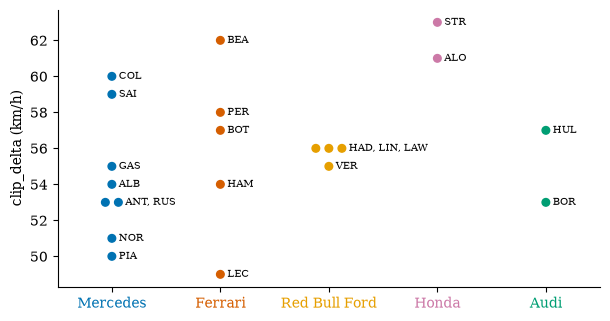

In [25]:
d = STRAIGHTS["T14→T16 via 130R"]
order = list(PU_COLORS)
tie = d.groupby(["PU", "clip_delta"])
x = d.PU.map(order.index) + 0.12 * (tie.cumcount() - (tie.Driver.transform("size") - 1) / 2)  # spread tied values only

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(x, d.clip_delta, c=d.PU.map(PU_COLORS), s=30, zorder=3)
for (pu, val), g in tie:
    ax.annotate(", ".join(g.Driver), (x[g.index].max(), val), xytext=(5, 0), textcoords="offset points", fontsize=7, va="center")
ax.set_xticks(range(len(order)), order)
for t, pu in zip(ax.get_xticklabels(), order):
    t.set_color(PU_COLORS[pu])
ax.set(xlim=(-0.5, len(order) - 0.5), ylabel="clip_delta (km/h)")
fig.savefig(FIG / "fig_t16_clip_delta_by_pu.pdf")
plt.show()

*Figure 3. clip_delta on the T14→T16 straight (through 130R) per driver, coloured by PU: 49–63 km/h across 21 drivers. One or two cars per team and one lap each; no PU ranking is implied.*

## 9. Reference figures

**A. Circuit map** (after Bopaiah & Samuel, 2021, Fig. 4), drawn from one lap's position data, which freezes do not affect. Rotation and corner-label offsets follow the FastF1 example *Draw a track map with numbered corners* (`get_circuit_info().rotation`, corner `Angle`). Sectors from the lap's sector timestamps; measured straights from the median start/end positions of the selected segments. Panel B: every frozen car-data sample on every push lap, placed at the nearest position sample. **B. Taper**: the FIA power limits used for `taper_kw_at_peak`, with each selected segment's peak speed.

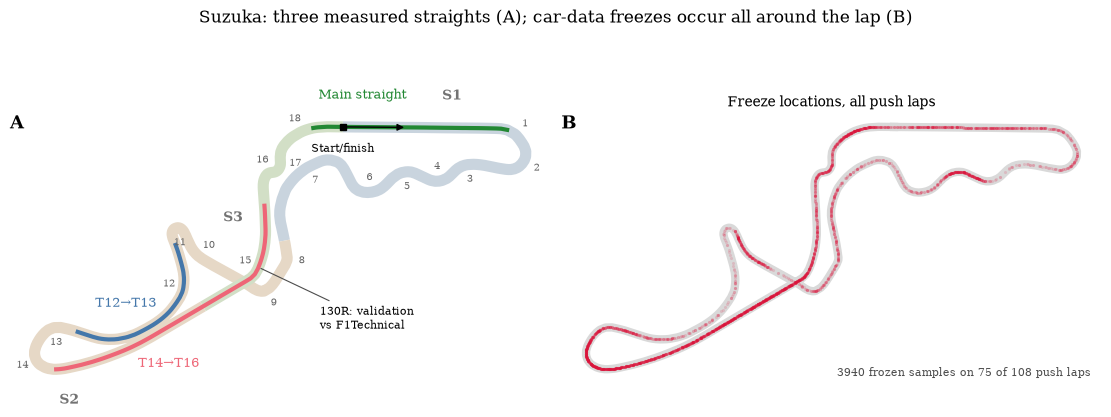

In [26]:
def rotate(xy, angle):
    """Rotate [n, 2] or [2] coordinates by `angle` radians (FastF1 track-map example)."""
    return np.matmul(xy, np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]]))


def place_label(ax, xy, idx, text, taken, dist=1300, **kw):
    """Write `text` beside the track near samples `idx`, at the candidate point (either side, `dist` units along the
    normal) furthest from the track and from points in `taken`; the chosen point is appended to `taken`."""
    best, best_gap = None, -1
    for i in idx:
        t = xy[min(i + 2, len(xy) - 1)] - xy[max(i - 2, 0)]
        nrm = np.array([-t[1], t[0]]) / np.hypot(*t)
        for sign in (1, -1):
            cand = xy[i] + sign * dist * nrm
            gap = np.hypot(*(np.vstack([xy, taken]) - cand).T).min()
            if gap > best_gap:
                best, best_gap = cand, gap
    taken.append(best)
    ax.text(*best, text, ha="center", va="center", **kw)


ci = s.get_circuit_info()
ang = ci.rotation / 180 * np.pi
ref = fastest["RUS"]
pos = lap_pos(ref)
xy, xyd = rotate(pos[["X", "Y"]].to_numpy(), ang), xy_cumdist(pos)
pt = pos["SessionTime"].dt.total_seconds().to_numpy()
i1, i2 = (int(np.abs(pt - ref[c].total_seconds()).argmin()) for c in ("Sector1SessionTime", "Sector2SessionTime"))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
taken = []
for n, c in corners.iterrows():
    off = rotate([600, 0], c.Angle / 180 * np.pi)
    pc = rotate([c.X + off[0], c.Y + off[1]], ang)
    axA.text(*pc, str(n), fontsize=7, color="0.4", ha="center", va="center")
    taken.append(pc)
p15 = rotate([corners.loc[15, "X"], corners.loc[15, "Y"]], ang)
note = p15 + np.array([2500, -2500])
axA.annotate("130R: validation\nvs F1Technical", xy=p15, xytext=note, fontsize=8, arrowprops=dict(arrowstyle="-", color="0.3", lw=0.8))
taken.append(note)
for (a, b), col, name in zip([(0, i1 + 1), (i1, i2 + 1), (i2, len(xy))], ["#c9d4de", "#e6d8c6", "#d2dfc6"], ["S1", "S2", "S3"]):
    axA.plot(*xy[a:b].T, color=col, lw=8, solid_capstyle="butt", zorder=1)
    place_label(axA, xy, np.linspace(a, b - 1, 7).astype(int)[1:-1], name, taken, fontsize=10, color="0.45", fontweight="bold")

ms = main_straight
spans = {"T13": [(straights.loc[straights.Label == "T13", "StartPos_m"].median(), straights.loc[straights.Label == "T13", "EndPos_m"].median())],
         "T16": [(straights.loc[straights.Label == "T16", "StartPos_m"].median(), straights.loc[straights.Label == "T16", "EndPos_m"].median())],
         "T1": [(xyd[-1] + ms.start_m.median(), xyd[-1]), (0, ms.end_m.median())]}
names = {"T13": "T12→T13", "T16": "T14→T16", "T1": "Main straight"}
for lab, parts in spans.items():
    for lo, hi in parts:
        m = (xyd >= lo) & (xyd <= hi)
        axA.plot(*xy[m].T, color=STRAIGHT_COLORS[lab], lw=3, zorder=2)
    lo, hi = parts[-1]
    i_mid = int(np.abs(xyd - (lo + hi) / 2).argmin())
    place_label(axA, xy, range(max(i_mid - 10, 0), min(i_mid + 11, len(xy)), 5), names[lab], taken, fontsize=9, color=STRAIGHT_COLORS[lab])

axA.plot(*xy[0], marker="s", color="black", ms=5, zorder=3)
axA.text(xy[0][0], xy[0][1] - 650, "Start/finish", fontsize=8, ha="center", va="top")
k = int(np.abs(xyd - 250).argmin())
axA.annotate("", xy=xy[k], xytext=xy[0], arrowprops=dict(arrowstyle="-|>", color="black", lw=1), zorder=4)

fx, fy, nlap = [], [], 0
for _, lap in push.iterlaps():
    car = lap.get_car_data()
    t_fz = car.loc[freeze_mask(car)[0], "SessionTime"].dt.total_seconds().to_numpy()
    if len(t_fz):
        nlap += 1
        p = lap.get_pos_data(pad=1, pad_side="both")
        j = np.abs(p["SessionTime"].dt.total_seconds().to_numpy()[:, None] - t_fz[None, :]).argmin(axis=0)
        r = rotate(p[["X", "Y"]].to_numpy()[j], ang)
        fx += list(r[:, 0]); fy += list(r[:, 1])
axB.plot(*xy.T, color="0.85", lw=6, zorder=1)
axB.scatter(fx, fy, s=5, color="crimson", alpha=0.15, lw=0, zorder=2)
axB.text(0.98, 0.02, f"{len(fx)} frozen samples on {nlap} of {len(push)} push laps", transform=axB.transAxes, fontsize=8, color="0.3", ha="right")

for ax, letter in [(axA, "A"), (axB, "B")]:
    ax.set_aspect("equal"); ax.axis("off")
    ax.text(0, 1, letter, transform=ax.transAxes, fontsize=13, fontweight="bold", va="top")
axB.set_title("Freeze locations, all push laps", fontsize=10)
fig.suptitle("Suzuka: three measured straights (A); car-data freezes occur all around the lap (B)", fontsize=12)
fig.savefig(FIG / "fig_suzuka_map.pdf")
plt.show()

*Figure 4. Suzuka reference map. A: FIA sectors (muted), corner numbers, start/finish with direction of travel, the three measured straights, and T15 (130R), used for Validation 2. B: 3,940 frozen car-data samples from 75 of 108 push laps, spread around the whole lap.*

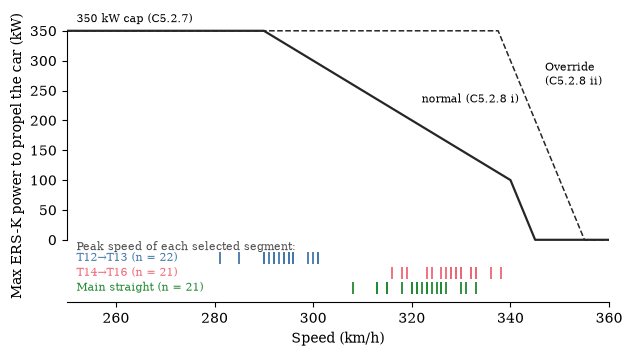

In [27]:
v = np.linspace(250, 360, 1101)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(v, taper_kw(v), color="0.15", lw=1.6)
ax.plot(v, np.minimum(np.where(v < 355, 7100 - 20 * v, 0), 350), color="0.15", lw=1.1, ls="--")  # C5.2.8 ii, C5.2.7 cap
ax.text(322, 230, "normal (C5.2.8 i)", fontsize=8)
ax.text(347, 260, "Override\n(C5.2.8 ii)", fontsize=8)
ax.text(252, 360, "350 kW cap (C5.2.7)", fontsize=8, va="bottom")
ax.text(252, -12, "Peak speed of each selected segment:", fontsize=8, va="center", color="0.3")

bands = {"T13": "T12→T13", "T16": "T14→T16", "T1": "Main straight"}
for i, (lab, name) in enumerate(bands.items()):
    pk = segments.loc[segments.Label == lab, "peak_speed"]
    y = -30 - 25 * i
    ax.plot(pk, np.full(len(pk), y), "|", ms=9, mew=1.3, color=STRAIGHT_COLORS[lab])
    ax.text(252, y, f"{name} (n = {len(pk)})", fontsize=8, va="center", color=STRAIGHT_COLORS[lab])
ax.set(xlim=(250, 360), ylim=(-105, 385), xlabel="Speed (km/h)", ylabel="Max ERS-K power to propel the car (kW)")
ax.set_yticks(range(0, 351, 50))
ax.spines["left"].set_bounds(0, 350)
fig.savefig(FIG / "fig_taper.pdf")
plt.show()

*Figure 5. Maximum ERS-K power used to propel the car vs speed, FIA 2026 Technical Regulations Section C, Issue 12: C5.2.8 i (solid), Override C5.2.8 ii (dashed), both capped at 350 kW by C5.2.7. Ticks: peak speed of each selected segment; T12→T13 peaks (281–301 km/h) lie around the 290 km/h start of the taper, T14→T16 and main-straight peaks (308–338 km/h) lie on the taper.*

## 10. Pipeline function

`run_session(year, event)` runs the whole chain above for one qualifying session (load, Validation 1, freeze flags, push-lap selection, sectors and PKE, segments and metrics, coverage, exclusion log) and returns the tables plus a QC summary. Event-specific checks (Validation 2 at 130R) stay outside. Japan is rerun through it and checked against the notebook.

In [28]:
def run_session(year, event, official_length_m=None):
    """Validation and metrics pipeline for one qualifying session. Returns (tables, qc summary dict)."""
    ses = load_quali(year, event)
    crn = ses.get_circuit_info().corners.set_index("Number")
    fl = {d: lap for d in ses.results["Abbreviation"] if (lap := ses.laps.pick_drivers(d).pick_fastest()) is not None}
    v1_ = lap_distance_check(fl, official_length_m) if official_length_m else None
    push_, lap_log_ = push_laps(ses)
    sec_all_, seg_all_ = sector_segment_rows(push_, crn)
    ms_all_ = main_straight_rows(ses, push_)
    sectors_, straights_, main_, segments_ = select_clean(sec_all_, seg_all_, ms_all_)
    frozen = pd.DataFrame([dict(PU=PU[lap["Team"]], FrozenPct=100 * freeze_mask(lap.get_car_data())[0].mean())
                           for _, lap in push_.iterlaps()])
    cols = ["Scope", "Driver", "LapNumber", "QualiPart", "Item", "Reason"]
    excl = pd.concat([
        lap_log_.assign(Scope="lap", Item=""),
        sec_all_[sec_all_.Frozen].assign(Scope="sector", Item=lambda x: x.Sector, Reason="overlaps freeze or missing sector time"),
        seg_all_[seg_all_.Frozen | seg_all_.Truncated].assign(
            Scope="straight", Item=lambda x: x.Label, Reason=lambda x: np.where(x.Frozen, "overlaps freeze", "truncated by lap boundary")),
        ms_all_[ms_all_.Status != "ok"].assign(Scope="main straight", Item="T1", Reason=lambda x: x.Status),
    ])[cols]
    err = (lambda c, f: getattr(v1_[c].abs(), f)()) if v1_ is not None else (lambda c, f: np.nan)
    qc = {"drivers": len(fl), "timed_laps": int(ses.laps["LapTime"].notna().sum()), "push_laps": len(push_),
          "lap_exclusions": len(lap_log_),
          "v1_car_mean_abs_err_pct": err("CarData_err%", "mean"), "v1_car_max_abs_err_pct": err("CarData_err%", "max"),
          "v1_xy_mean_abs_err_pct": err("XY_err%", "mean"), "v1_xy_max_abs_err_pct": err("XY_err%", "max"),
          "push_lap_frozen_pct_mean": frozen.FrozenPct.mean(),
          "sectors_computed": len(sec_all_), "sectors_dropped": int(sec_all_.Frozen.sum()), "sectors_selected": len(sectors_),
          "segments_detected": len(seg_all_), "segments_dropped": int((seg_all_.Frozen | seg_all_.Truncated).sum()),
          "straights_selected": len(straights_), "main_straight_ok": int((ms_all_.Status == "ok").sum()),
          "main_straight_drivers": len(main_), "segment_rows": len(segments_)}
    tables = dict(v1=v1_, push=push_, sectors=sectors_, segments=segments_, exclusions=excl,
                  coverage=pd.concat({"sector": sectors_.groupby("Sector").Driver.nunique(),
                                      "straight": segments_.groupby("Label").Driver.nunique()}),
                  frozen_by_pu=frozen.groupby("PU").FrozenPct.mean())
    return tables, qc


tables_jp, qc_jp = run_session(2026, "Japan", OFFICIAL_LENGTH_M)

notebook = {"drivers": len(fastest), "timed_laps": len(timed), "push_laps": len(push), "lap_exclusions": len(lap_log),
            "v1_car_mean_abs_err_pct": v1["CarData_err%"].abs().mean(), "v1_car_max_abs_err_pct": v1["CarData_err%"].abs().max(),
            "v1_xy_mean_abs_err_pct": v1["XY_err%"].abs().mean(), "v1_xy_max_abs_err_pct": v1["XY_err%"].abs().max(),
            "push_lap_frozen_pct_mean": qc.loc[qc.Push, "FrozenPct"].mean(),
            "sectors_computed": len(sec_all), "sectors_dropped": int(sec_all.Frozen.sum()), "sectors_selected": len(sectors),
            "segments_detected": len(seg_all), "segments_dropped": len(seg_log), "straights_selected": len(straights),
            "main_straight_ok": int((ms_all.Status == "ok").sum()), "main_straight_drivers": len(main_straight),
            "segment_rows": len(segments)}
check = pd.DataFrame({"notebook": notebook, "run_session": qc_jp})
check["match"] = [np.isclose(a, b) for a, b in zip(check.notebook, check.run_session)]
print(check.round(3).to_string())
assert check["match"].all()
pd.testing.assert_frame_equal(tables_jp["sectors"].reset_index(drop=True), sectors.reset_index(drop=True))
pd.testing.assert_frame_equal(tables_jp["segments"].reset_index(drop=True), segments.reset_index(drop=True))
print("\nAll headline numbers and the sectors/segments tables match.\n")
print(tables_jp["exclusions"].groupby(["Scope", "Reason"]).size().rename("rows").to_string())

                          notebook  run_session  match
drivers                     22.000       22.000   True
timed_laps                 227.000      227.000   True
push_laps                  108.000      108.000   True
lap_exclusions             119.000      119.000   True
v1_car_mean_abs_err_pct      1.483        1.483   True
v1_car_max_abs_err_pct       7.366        7.366   True
v1_xy_mean_abs_err_pct       0.584        0.584   True
v1_xy_max_abs_err_pct        0.827        0.827   True
push_lap_frozen_pct_mean    10.602       10.602   True
sectors_computed           432.000      432.000   True
sectors_dropped            241.000      241.000   True
sectors_selected            75.000       75.000   True
segments_detected          271.000      271.000   True
segments_dropped           123.000      123.000   True
straights_selected          43.000       43.000   True
main_straight_ok            65.000       65.000   True
main_straight_drivers       21.000       21.000   True
segment_ro

*Table 17. run_session(2026, "Japan") reproduces all 18 headline numbers and the sectors and segments tables exactly; its exclusion log covers laps, sectors, straights and the main straight.*

## Appendix A: OpenF1 comparison

ANT's 25.8 s freeze queried from OpenF1 `car_data` for the same UTC window and matched to FastF1 samples within 20 ms. Not part of the pipeline.

In [29]:
lap = fastest["ANT"]
car = lap.get_car_data()
_, core, run_id = freeze_mask(car)
ff = car.loc[run_id == run_id[core].value_counts().idxmax(), ["Date", "Speed", "RPM", "nGear", "Throttle"]]
url = (f"https://api.openf1.org/v1/car_data?session_key={OPENF1_SESSION}&driver_number={lap['DriverNumber']}"
       f"&date>={ff['Date'].iloc[0]:%Y-%m-%dT%H:%M:%S.%f}&date<={ff['Date'].iloc[-1]:%Y-%m-%dT%H:%M:%S.%f}")
of = pd.DataFrame(json.load(urllib.request.urlopen(url)))
of["Date"] = pd.to_datetime(of["date"], format="ISO8601").dt.tz_localize(None).astype(ff["Date"].dtype)
m = pd.merge_asof(ff, of.assign(OpenF1Date=of["Date"]).sort_values("Date"), on="Date", direction="nearest")
m = m[(m["Date"] - m["OpenF1Date"]).abs() <= pd.Timedelta(milliseconds=20)]
same = all((m[a] == m[b]).all() for a, b in [("Speed", "speed"), ("RPM", "rpm"), ("nGear", "n_gear"), ("Throttle", "throttle")])
print(f"FastF1 samples: {len(ff)}, OpenF1 samples: {len(of)}, matched: {len(m)}, all channels identical: {same}")
print("OpenF1 values:", {c: sorted(of[c].unique().tolist()) for c in ["speed", "rpm", "n_gear", "throttle", "brake"]})

FastF1 samples: 96, OpenF1 samples: 96, matched: 96, all channels identical: True
OpenF1 values: {'speed': [189], 'rpm': [11535], 'n_gear': [4], 'throttle': [80, 104], 'brake': [0, 104]}


*Table A1. All 96 frozen samples are identical in OpenF1, which also reports `brake == 104` during the freeze.*

## Appendix B: diagnostics

Evidence behind the decisions above, kept for reproducibility.

**B1. Distance-error causes on fastest laps.** `add_distance` integrates `Speed / 3.6 · dt` with `dt[0] = Time[0]` (core.py), so gaps are counted at the post-gap speed, the lap start is covered and the stretch from the last sample to the lap end is not. With `pad=1`, `Time` stays relative to lap start, so the pad sample has negative `Time` and is not double-counted.

In [30]:
def unchanged_runs(car, cols, end):
    """Runs of consecutive samples with all `cols` unchanged: i0, i1, samples, duration (s)."""
    new = car[cols].ne(car[cols].shift()).any(axis=1).to_numpy()
    t = np.append(car["SessionTime"].dt.total_seconds().to_numpy(), end.total_seconds())
    i0 = np.flatnonzero(new)
    i1 = np.append(i0[1:], len(car))
    return pd.DataFrame(dict(i0=i0, i1=i1, n=i1 - i0, Duration_s=t[i1] - t[i0]))


diag = []
for d, lap in fastest.items():
    raw = lap.get_car_data().add_distance()
    pad = lap.get_car_data(pad=1, pad_side="both").add_distance()
    sl = pad.slice_by_lap(lap, interpolate_edges=True)
    t = raw["SessionTime"].dt.total_seconds()
    tail = lap["Time"].total_seconds() - t.iloc[-1]
    flag, core, run_id = freeze_mask(raw)
    starts_full = run_id.map(raw.groupby(run_id)["Throttle"].first()).between(98, 100)
    diag.append(dict(Driver=d, Head_s=t.iloc[0] - lap["LapStartTime"].total_seconds(), Tail_s=tail,
                     Gaps_over_0p5s=int((t.diff() > 0.5).sum()), MaxGap_s=t.diff().max(),
                     LongestSpeedRun=unchanged_runs(raw, ["Speed"], lap["Time"]).n.max(),
                     PadTime0_s=pad["Time"].iloc[0].total_seconds(),
                     PadMinusRaw_m=sl["Distance"].iloc[-1] - sl["Distance"].iloc[0] - raw["Distance"].iloc[-1],
                     TailExpected_m=raw["Speed"].iloc[-1] / 3.6 * tail,
                     Frozen_n=int(flag.sum()), FrozenFromFullThrottle_n=int((core & starts_full).sum())))
print(pd.DataFrame(diag).set_index("Driver").round(2).to_string())

        Head_s  Tail_s  Gaps_over_0p5s  MaxGap_s  LongestSpeedRun  PadTime0_s  PadMinusRaw_m  TailExpected_m  Frozen_n  FrozenFromFullThrottle_n
Driver                                                                                                                                          
ANT       0.01    0.05               6      1.08               96       -0.15           2.63            2.63       109                        10
RUS       0.16    0.16               5      1.08               14       -0.08          11.62           11.45        16                        14
PIA       0.09    0.00               2      1.08                4       -0.07           0.18            0.15         0                         0
LEC       0.02    0.01               5      1.08               14       -0.14           0.44            0.45        16                        14
NOR       0.13    0.08               3      1.08                6       -0.07           6.11            6.05         0            

*Table B1. Coverage, gaps and padding do not explain the distance errors: first/last samples are within 0.41 s of the lap boundaries, padded − unpadded equals the uncovered tail within 0.5 m, and the largest errors occur on heavily frozen laps (ANT, BOR, OCO, COL).*

**B2. Why the freeze is seeded on 104 rather than on all channels being unchanged.** Throttle and Brake switch to 104 inside a freeze, so requiring all five channels to be unchanged splits one freeze into several runs.

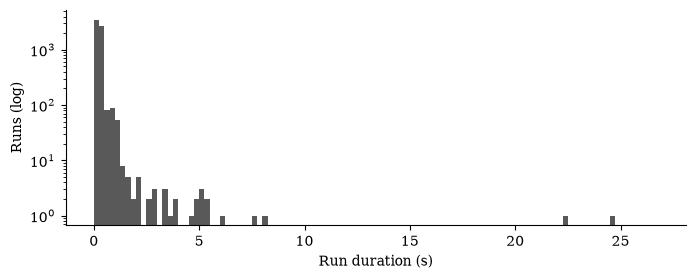

Longest Speed-only run outside ANT/BOR: ALB, 36 samples, 9.1 s at 308 km/h; distinct values: {'Speed': 1, 'RPM': 1, 'nGear': 1, 'Throttle': 2, 'Brake': 2}


In [31]:
CH = ["Speed", "RPM", "nGear", "Throttle", "Brake"]
r5 = pd.concat([unchanged_runs(lap.get_car_data(), CH, lap["Time"]).assign(Driver=d) for d, lap in fastest.items()])
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(r5["Duration_s"], bins=np.arange(0, 27, 0.25), log=True, color="0.35")
ax.set(xlabel="Run duration (s)", ylabel="Runs (log)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

rs = pd.concat([unchanged_runs(lap.get_car_data(), ["Speed"], lap["Time"]).assign(Driver=d)
                for d, lap in fastest.items() if d not in ("ANT", "BOR")]).sort_values("n").iloc[-1]
seg = fastest[rs.Driver].get_car_data().iloc[int(rs.i0):int(rs.i1)]
print(f"Longest Speed-only run outside ANT/BOR: {rs.Driver}, {int(rs.n)} samples, {rs.Duration_s:.1f} s at {seg.Speed.iloc[0]:.0f} km/h; "
      f"distinct values: {seg[CH].nunique().to_dict()}")

*Figure B1. Durations of runs with all five channels unchanged (22 fastest laps): most last < 1 s, a tail reaches ~8 s, then ANT and BOR at 22–25 s; ALB's 9.1 s Speed freeze is split because Throttle and Brake change inside it.*

**B3. Where the two longest freezes sit on the lap.** Lap position from X/Y path length; corners placed by nearest X/Y point on the same lap.

In [32]:
for d in ["ANT", "BOR"]:
    lap = fastest[d]
    car = lap.get_car_data().add_distance()
    pos = lap_pos(lap)
    xyd, pt = xy_cumdist(pos), pos["SessionTime"].dt.total_seconds().to_numpy()
    i0, i1, t0, t1 = max(blocks(car, freeze_mask(car)[1], lap["Time"]), key=lambda b: b[1] - b[0])
    tc = car["SessionTime"].dt.total_seconds()
    d0, d1 = (xyd[np.abs(pt - x).argmin()] for x in (tc.iloc[i0 - 1], t1))
    car_m = car["Distance"].iloc[i1 - 1] - car["Distance"].iloc[i0 - 1] + car["Speed"].iloc[i1 - 1] / 3.6 * (t1 - tc.iloc[i1 - 1])
    inside = [f"T{n}" for n, c in corners.iterrows() if d0 <= xyd[np.hypot(pos.X - c.X, pos.Y - c.Y).argmin()] <= d1]
    print(f"{d}: {t1 - t0:.1f} s frozen, lap position {d0:.0f}-{d1:.0f} m (X/Y), corners {', '.join(inside)}; "
          f"distance over window: car data {car_m:.0f} m vs X/Y {d1 - d0:.0f} m")

ANT: 25.8 s frozen, lap position 3979-5769 m (X/Y), corners T15, T16, T17, T18; distance over window: car data 1380 m vs X/Y 1789 m
BOR: 24.0 s frozen, lap position 3273-5087 m (X/Y), corners T13, T14, T15; distance over window: car data 1898 m vs X/Y 1814 m


*Table B3. ANT's freeze covers T15–T18 (car data −409 m vs X/Y), BOR's covers T13–T15 (+84 m): both include 130R.*

**B4. Frozen share of every timed lap** (driver × lap number; `*` = push lap).

In [33]:
v = qc.assign(v=qc.FrozenPct.round().astype(int).astype(str) + np.where(qc.Push, "*", ""))
print(v.pivot(index="Driver", columns="LapNumber", values="v").reindex(list(fastest)).fillna(".").to_string())

LapNumber   2   3   4    5   6    7    8   9    10   11   12   13   14  15  16   17 18   19   20  21
Driver                                                                                              
ANT         0*   4   .   5*   9    .  24*  17    .  33*   66    .  32*  10   .    .  .    .    .   .
RUS         0*   2   .  23*  20    .   1*   3    .  11*    7    2   0*   4   .   5*  0    .  15*  14
PIA         2*   0  2*    2   .  14*    4   .   0*    3    .  19*   16   .  0*    2  .  13*   10   .
LEC        21*  11   0   0*   3    .   5*   0    .   5*    0    .   0*   0   .   0*  .    .    .   .
NOR         0*   2  0*    5   .  26*    8   .   0*    3    .  12*   13   .  0*    3  .   1*    2   .
HAM         2*   2   3   2*   4    .   0*   2    .   0*    2   0*    2   .  0*    0  .   0*    0   .
GAS         2*   4   .  10*  11    .  13*  13    .  23*   23    .   8*  10   .  10*  4    .    .   .
HAD         1*   4   .  15*  10    .   0*   0    .   7*    5    .   4*   3   .    2  .    .

*Table B4. Freezes vary from lap to lap for most drivers rather than affecting a whole car for the session.*

**B5. Stale runs without the sentinel.** A run of unchanged Speed + RPM + nGear lasting >= 1.5 s that contains no `Throttle == 104` is not flagged by the freeze definition. Checked on STR's two selected straights, then on every selected segment.

STR T13 (lap 5, Q1): segment 2946-3701 m, peak 285 km/h at vmax_position 0.59, clip_delta 48, PKE 6.39
  no stale run >= 1.5 s


STR T16 (lap 8, Q1): segment 4607-5241 m, peak 316 km/h at vmax_position 0.05, clip_delta 63, PKE 0.00


  no stale run >= 1.5 s


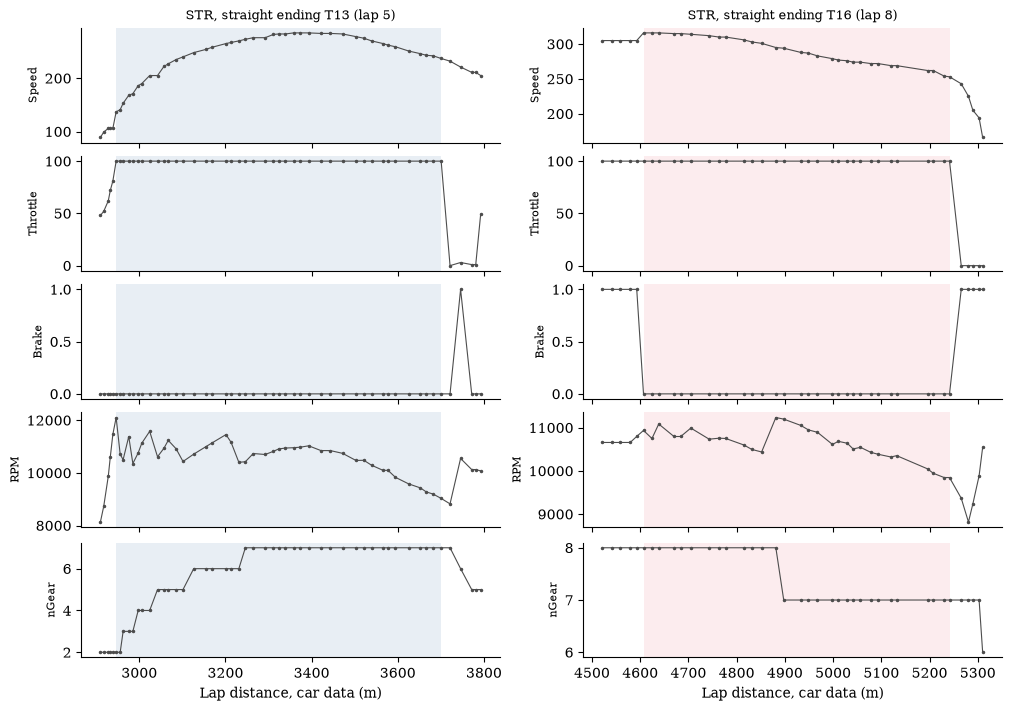

In [34]:
def segment_car(row):
    """Car data, end time and sample range [i0, i1) of one selected segment."""
    lap = push[(push.Driver == row.Driver) & (push.LapNumber == row.LapNumber)].iloc[0]
    car = line_window(s, lap)[0] if row.CrossesTimingLine else lap.get_car_data().add_distance()
    end = car["SessionTime"].iloc[-1] if row.CrossesTimingLine else lap["Time"]
    i = np.flatnonzero((car["Distance"] >= row.start_m) & (car["Distance"] <= row.end_m))
    return car, end, i[0], i[-1] + 1


def stale_runs(car, end, i0, i1, min_s=1.5):
    """Unchanged Speed+RPM+nGear runs lasting >= min_s that overlap samples [i0, i1), and whether each contains 104."""
    r = unchanged_runs(car, ["Speed", "RPM", "nGear"], end)
    r = r[(r.Duration_s >= min_s) & (r.i0 < i1) & (r.i1 > i0)].copy()
    r["Has104"] = [bool((car["Throttle"].iloc[a:b] == SENTINEL).any()) for a, b in zip(r.i0, r.i1)]
    r["Speed"], r["Gear"], r["Dist_m"] = car["Speed"].iloc[r.i0].values, car["nGear"].iloc[r.i0].values, car["Distance"].iloc[r.i0].values
    return r


str_rows = segments[(segments.Driver == "STR") & segments.Label.isin(["T13", "T16"])]
fig, axes = plt.subplots(5, len(str_rows), figsize=(10, 7), sharex="col", layout="constrained")
for col, row in enumerate(str_rows.itertuples()):
    car, end, i0, i1 = segment_car(row)
    seg = car.iloc[max(i0 - 5, 0):i1 + 5]
    r = stale_runs(car, end, i0, i1)
    print(f"STR {row.Label} (lap {row.LapNumber}, {row.QualiPart}): segment {row.start_m:.0f}-{row.end_m:.0f} m, "
          f"peak {row.peak_speed:.0f} km/h at vmax_position {row.vmax_position:.2f}, clip_delta {row.clip_delta:.0f}, PKE {row.pke:.2f}")
    print(r[["n", "Duration_s", "Speed", "Gear", "Dist_m", "Has104"]].round(2).to_string(index=False) if len(r) else "  no stale run >= 1.5 s")
    for ax, ch in zip(axes[:, col], ["Speed", "Throttle", "Brake", "RPM", "nGear"]):
        ax.plot(seg["Distance"], seg[ch].astype(float), ".-", ms=3, lw=0.8, color="0.3")
        ax.axvspan(row.start_m, row.end_m, color=STRAIGHT_COLORS[row.Label], alpha=0.12, lw=0)
        for a, b in zip(r.i0, r.i1):
            ax.axvspan(car["Distance"].iloc[a], car["Distance"].iloc[min(b, len(car) - 1)], color="orange", alpha=0.35, lw=0)
        ax.set_ylabel(ch, fontsize=8)
    axes[0, col].set_title(f"STR, straight ending {row.Label} (lap {row.LapNumber})", fontsize=9)
    axes[-1, col].set_xlabel("Lap distance, car data (m)")
plt.show()

*Figure B2. STR's two selected straights (shaded: segment; orange: stale run >= 1.5 s, none found). T12→T13 shows consistent channels. Before the T14→T16 segment, Speed holds 305 km/h for ~1.6 s with Brake = True at Throttle = 100 while RPM still changes, then jumps to 316 km/h; the brake reading starts the segment at its peak (4607 m instead of ~4030 m), hence PKE 0.0.*

In [35]:
rows = []
for row in segments.itertuples():
    r = stale_runs(*segment_car(row))
    rows += [dict(Driver=row.Driver, Label=row.Label, LapNumber=row.LapNumber, **x) for x in r.drop(columns=["i0", "i1"]).to_dict("records")]
stale = pd.DataFrame(rows)
no104 = stale[~stale.Has104] if len(stale) else stale
print(f"Selected segments: {len(segments)}; with a stale run >= 1.5 s: {stale.groupby(['Driver', 'Label']).ngroups if len(stale) else 0}; "
      f"with one lacking Throttle == 104: {no104.groupby(['Driver', 'Label']).ngroups if len(no104) else 0}")
print(no104.round(2).to_string(index=False) if len(no104) else "none")

Selected segments: 64; with a stale run >= 1.5 s: 0; with one lacking Throttle == 104: 0
none


*Table B5. No selected segment overlaps an unchanged Speed+RPM+nGear run >= 1.5 s, so the 1.5 s check does not find STR's T14→T16 issue: there only Speed is stale, and only for ~1.6 s.*

In [36]:
bt = []
for _, lap in push.iterlaps():
    car = lap.get_car_data()
    flag, _, run_id = freeze_mask(car)
    hit = car["Brake"] & car["Throttle"].between(FULL_THROTTLE, 100) & ~flag
    bt.append(dict(Driver=lap["Driver"], LapNumber=int(lap["LapNumber"]), Samples=len(car), BrakeAtFull=int(hit.sum()),
                   InUnchangedRun3=int((hit & run_id.map(run_id.value_counts()).ge(3)).sum())))
bt = pd.DataFrame(bt)
print(f"Push-lap samples: {bt.Samples.sum()}; Brake = True with Throttle 98-100, not flagged as freeze: {bt.BrakeAtFull.sum()} samples "
      f"on {(bt.BrakeAtFull > 0).sum()} of {len(bt)} push laps; inside an unchanged Speed+RPM+nGear run of >= 3 samples: {bt.InUnchangedRun3.sum()}")

Push-lap samples: 36875; Brake = True with Throttle 98-100, not flagged as freeze: 167 samples on 70 of 108 push laps; inside an unchanged Speed+RPM+nGear run of >= 3 samples: 45


*Table B6. Brake = True at full throttle outside flagged freezes: 167 of 36,875 push-lap samples, on 70 of 108 push laps; 45 sit inside short unchanged Speed+RPM+nGear runs (>= 3 samples). Whether these are left-foot braking or stale data is not determined.*